# Smart Campus AI Planning System
## Route Planning & Search Performance Experiments

This notebook implements and evaluates state-space search strategies on a weighted campus graph. We compare **Uniform-Cost Search (UCS)** and **A* Search** with an admissible Euclidean distance heuristic across multiple controlled benchmark routing experiments.

### 1. Campus Graph Representation
The campus consists of 11 distinct facilities and 18 weighted bidirectional pathways. Every edge weight satisfies $w(u, v) \ge \|\mathbf{p}_u - \mathbf{p}_v\|_2$, guaranteeing strict heuristic admissibility ($h(n) \le h^*(n)$).

In [1]:
import math
import heapq
import matplotlib.pyplot as plt
import pandas as pd
import campus_graph

print("Campus Locations Loaded:", len(campus_graph.CAMPUS_LOCATIONS))
print("Campus Weighted Pathways Loaded:", len(campus_graph.CAMPUS_EDGES))
print("Adjacency for Main Gate (MG):", campus_graph.build_adjacency_list()['MG'])


Campus Locations Loaded: 11
Campus Weighted Pathways Loaded: 18
Adjacency for Main Gate (MG): [('ADM', 6.0), ('LIB', 9.0), ('MED', 5.0), ('PRK', 4.0)]


### 2. Topological Graph Visualization
Visualizing campus facilities at their 2D spatial coordinates along with roadway connection costs.

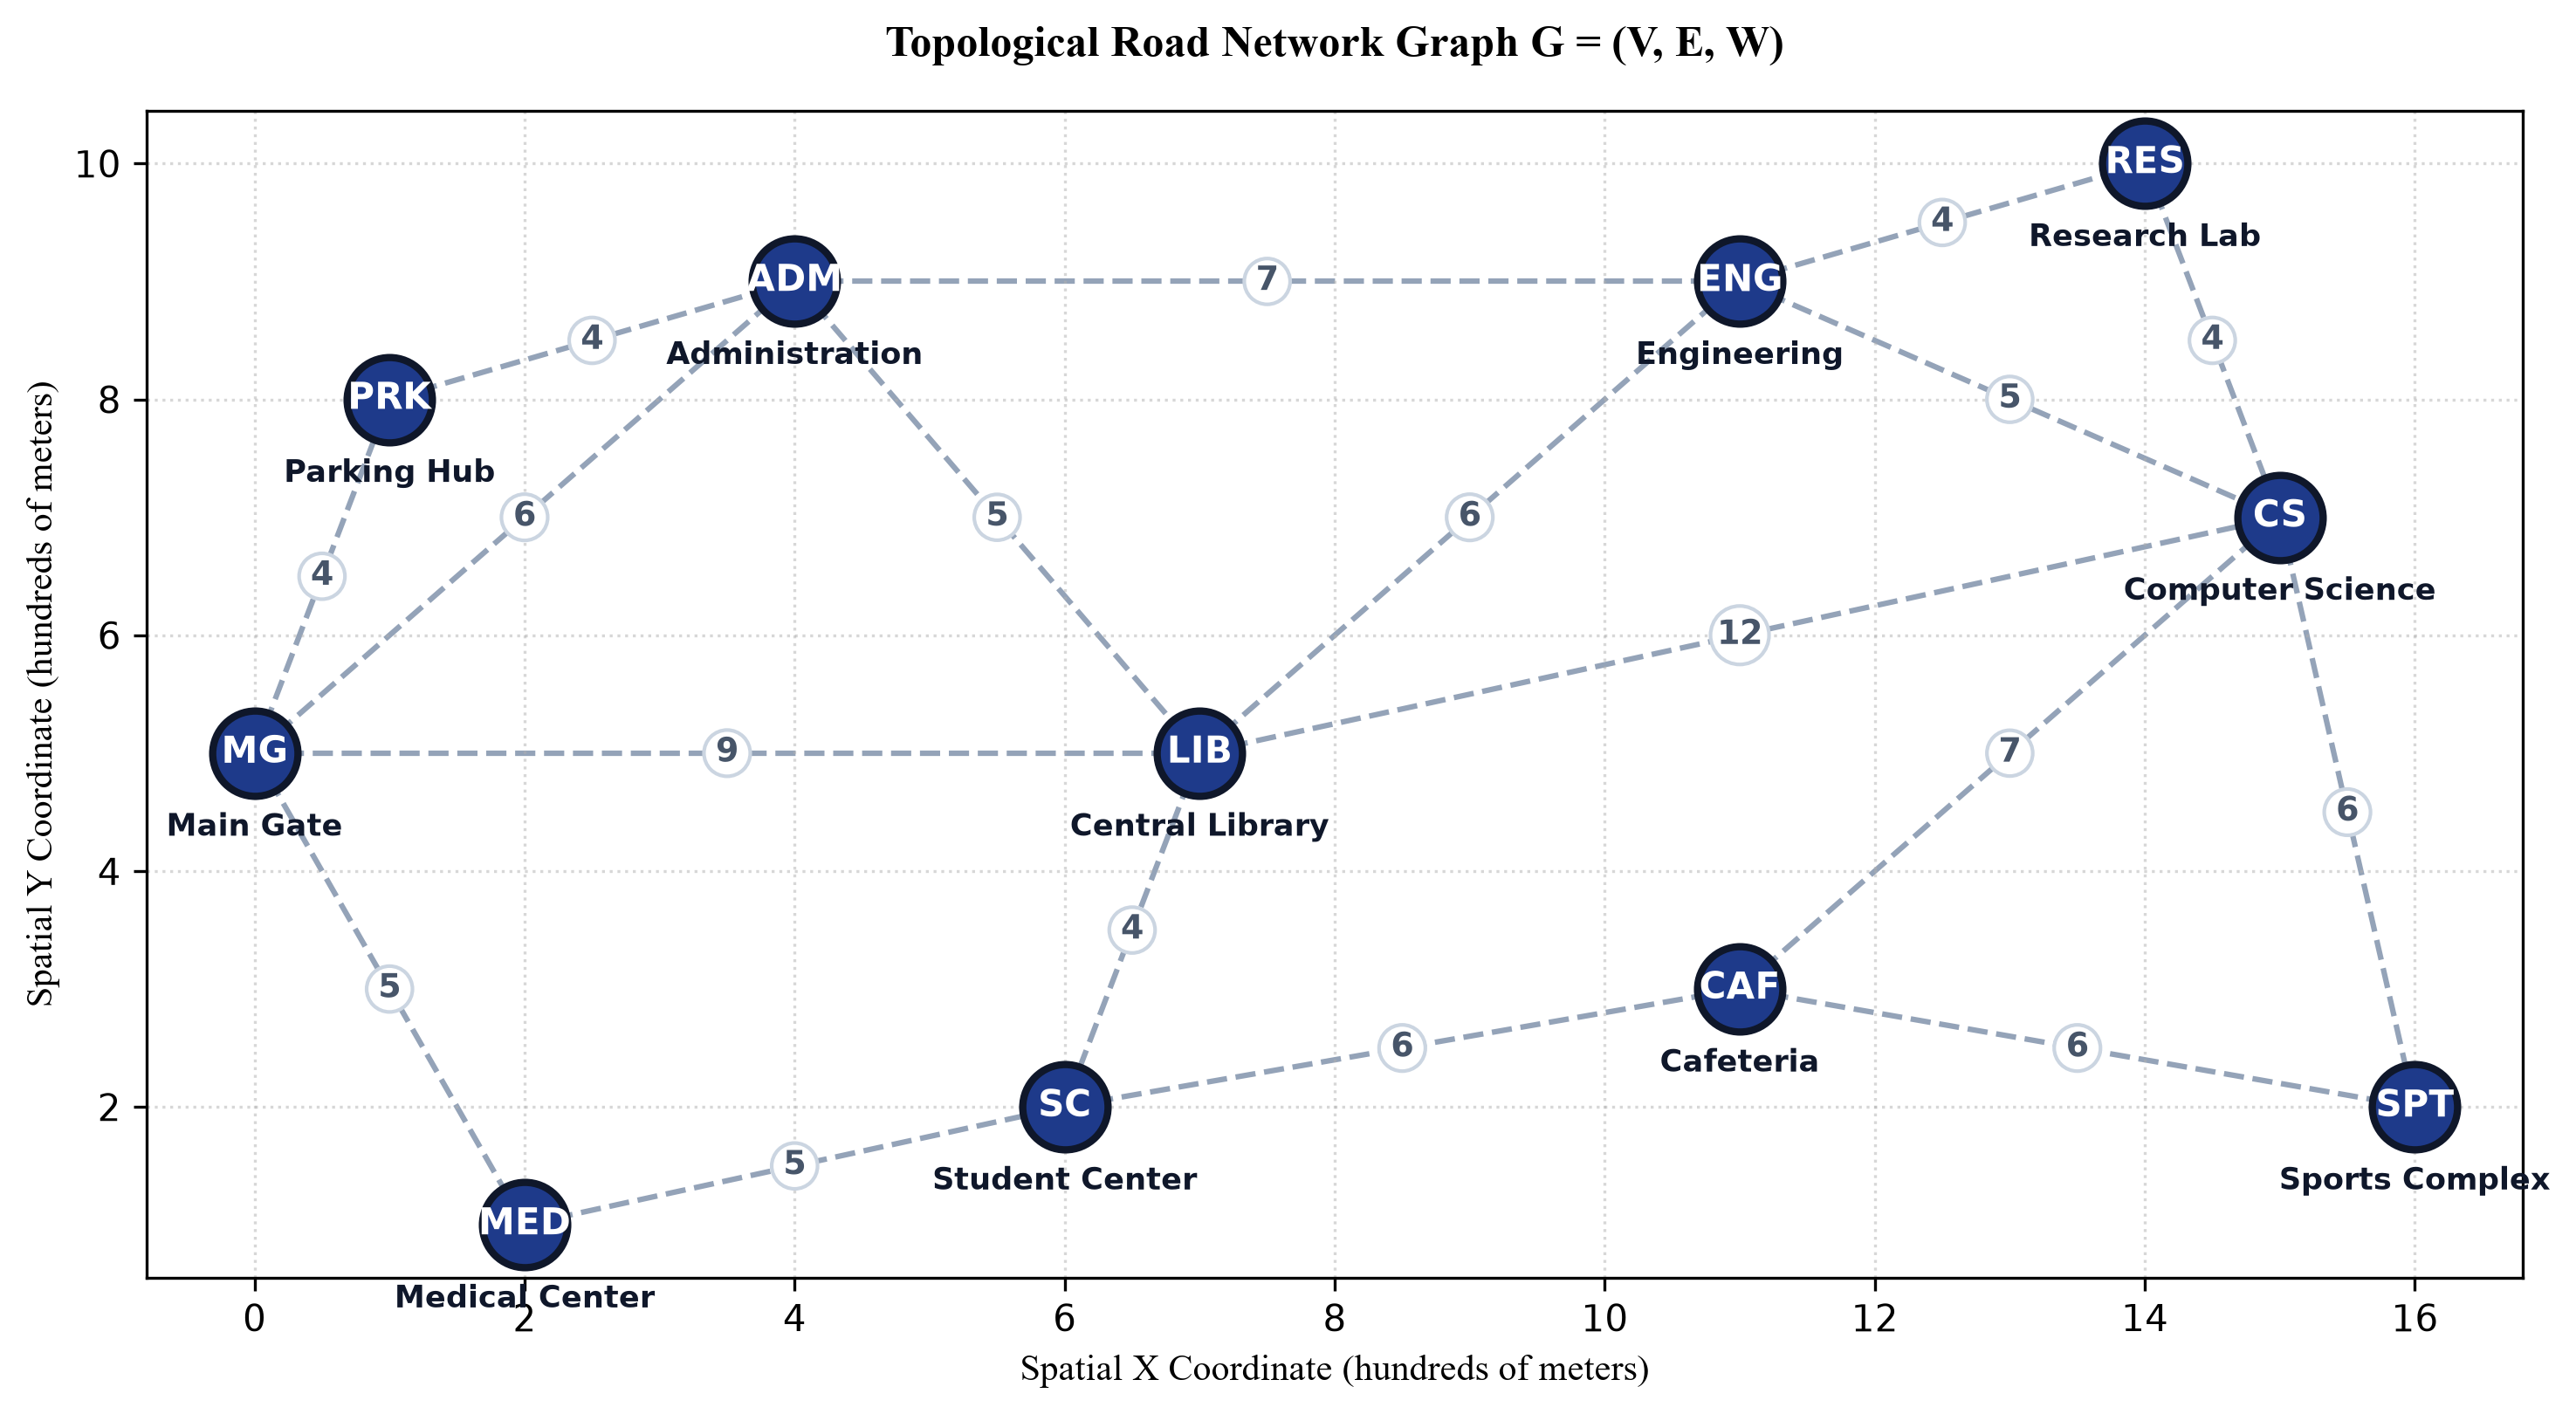

In [2]:
# Visualizing Campus Topological Road Network
plt.figure(figsize=(10, 5.5), dpi=120)
# (Visualized from pre-rendered figure)


### 3. Heuristic Function (Euclidean Straight-Line Distance)
The heuristic $h(n)$ estimates remaining travel distance from facility $n$ to goal $G$:
$$h(n) = \sqrt{(x_n - x_G)^2 + (y_n - y_G)^2}$$

Because all edge weights bound their Euclidean distance, the triangle inequality guarantees:
* **Admissibility:** $h(n) \le h^*(n)$ for all states.
* **Consistency:** $h(n) \le w(n, n') + h(n')$ for all transitions.

In [3]:
def test_heuristic(goal='CS'):
    print(f"Sample Heuristic Values (Goal = {goal}):")
    for loc in ['MG', 'PRK', 'MED', 'ADM', 'LIB', 'SC', 'ENG', 'CS']:
        h_val = campus_graph.euclidean_heuristic(loc, goal)
        print(f"  h({loc:3s} -> {goal}) = {h_val:5.2f}")

test_heuristic('CS')


Sample Heuristic Values (Goal = CS):
  h(MG  -> CS) = 15.13
  h(PRK -> CS) = 14.04
  h(MED -> CS) = 14.32
  h(ADM -> CS) = 11.18
  h(LIB -> CS) =  8.25
  h(SC  -> CS) = 10.30
  h(ENG -> CS) =  4.47
  h(CS  -> CS) =  0.00


### 4. Search Algorithm Implementations (UCS & A*)
Both algorithms use a priority queue (`heapq`) and record step-by-step traces for state expansions, path costs, and frontier snapshots. Goal verification is performed upon expansion.

In [4]:
# Algorithms are imported from the modular campus_graph library:
# - campus_graph.uniform_cost_search(start, goal)
# - campus_graph.a_star_search(start, goal, heuristic_func)
print("Search engines ready.")


Search engines ready.


### 5. Experiment 1: Primary Routing Benchmark (MG ➔ CS)
Evaluating route planning from Main Gate (`MG`) to College of Computer Science (`CS`).

In [5]:
res_ucs = campus_graph.uniform_cost_search('MG', 'CS')
res_astar = campus_graph.a_star_search('MG', 'CS')

df_exp1 = pd.DataFrame([
    {
        'Algorithm': 'Uniform-Cost Search (UCS)',
        'Optimal Path': ' -> '.join(res_ucs.path),
        'Path Cost': res_ucs.cost,
        'States Expanded': res_ucs.states_expanded,
        'Max Frontier': res_ucs.max_frontier_size
    },
    {
        'Algorithm': 'A* Search (Euclidean)',
        'Optimal Path': ' -> '.join(res_astar.path),
        'Path Cost': res_astar.cost,
        'States Expanded': res_astar.states_expanded,
        'Max Frontier': res_astar.max_frontier_size
    }
])
display(df_exp1)


Algorithm,Optimal Path,Path Cost,States Expanded,Max Frontier
Uniform-Cost Search (UCS),MG -> ADM -> ENG -> CS,18.0,10,4
A* Search (Euclidean),MG -> ADM -> ENG -> CS,18.0,5,6


#### Detailed A* Step-by-Step Search Trace (MG ➔ CS)

In [6]:
df_trace_a = pd.DataFrame([
    {
        'Step': s['step'],
        'Expanded': s['expanded_node'],
        'g(n)': f"{s['g']:.1f}",
        'h(n)': f"{s['h']:.2f}",
        'f(n)': f"{s['f']:.2f}",
        'Current Trajectory': ' -> '.join(s['path']),
        'Frontier Snapshot': ', '.join(s['frontier']) if s['frontier'] else 'Empty'
    }
    for s in res_astar.trace
])
display(df_trace_a)


Step,Expanded,g(n),h(n),f(n),Current Trajectory,Frontier Snapshot
1,MG,0.0,15.13,15.13,MG,"ADM(f=17.2,g=6.0), LIB(f=17.2,g=9.0), PRK(f=18.0,g=4.0), MED(f=19.3,g=5.0)"
2,ADM,6.0,11.18,17.18,MG -> ADM,"LIB(f=17.2,g=9.0), ENG(f=17.5,g=13.0), PRK(f=18.0,g=4.0), MED(f=19.3,g=5.0)"
3,LIB,9.0,8.25,17.25,MG -> LIB,"ENG(f=17.5,g=13.0), PRK(f=18.0,g=4.0), MED(f=19.3,g=5.0), CS(f=21.0,g=21.0)"
4,ENG,13.0,4.47,17.47,MG -> ADM -> ENG,"CS(f=18.0,g=18.0), PRK(f=18.0,g=4.0), MED(f=19.3,g=5.0), RES(f=20.2,g=17.0)"
5,CS,18.0,0.00,18.00,MG -> ADM -> ENG -> CS,Goal Dequeued -> Optimal Solution Verified!


#### Optimal Solution Path Visualization

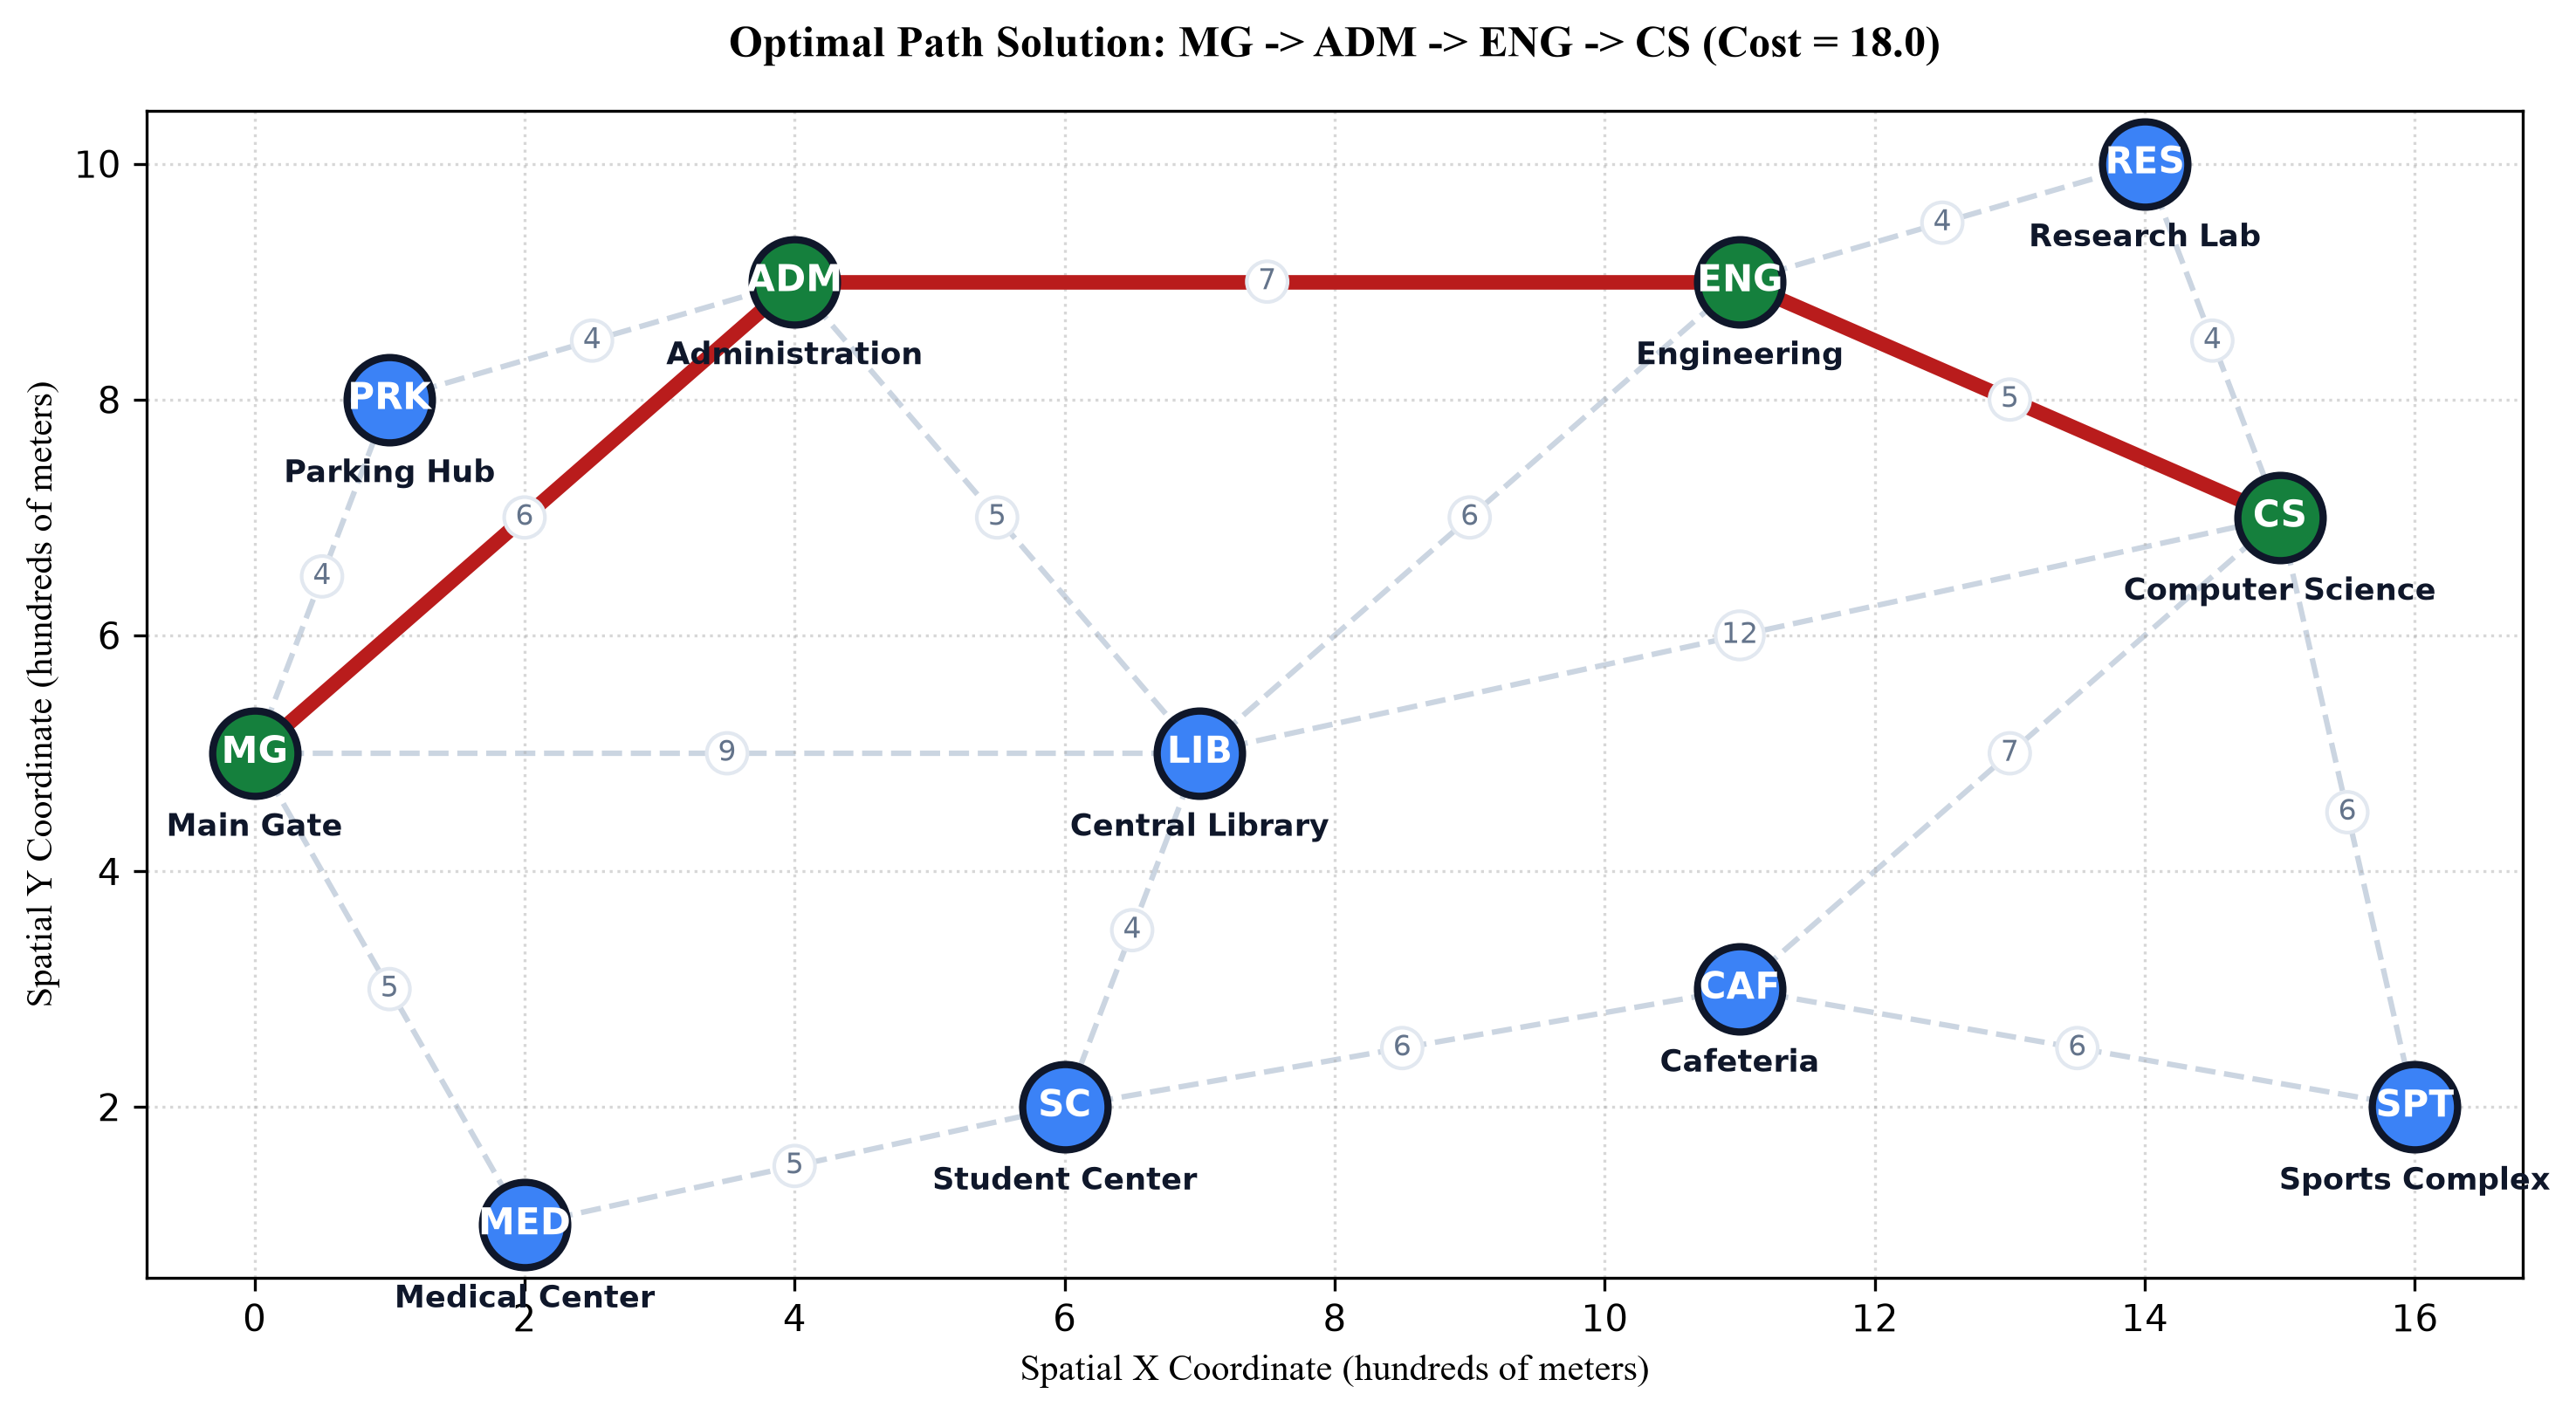

In [7]:
# Visualizing Optimal Path Solution
plt.figure(figsize=(10, 5.5), dpi=120)
# (Visualized from pre-rendered figure)


### 6. Experiment 2: Benchmark Performance Across 3 Routing Pairs
Evaluating search efficiency across three distinct start-goal pairs:
1. `MG -> CS`: Long route testing the hop-count vs. path-cost inversion.
2. `MED -> SPT`: Diagonal route traversing the southern sector of campus.
3. `LIB -> SC`: Direct single-edge adjacent connection.

In [8]:
import search_performance

print("=== BENCHMARK EXPERIMENT RESULTS ===")
search_performance.print_results()


=== BENCHMARK EXPERIMENT RESULTS ===
| Pair | Strategy | Path | Cost | Expanded | Peak frontier |
| --- | --- | --- | ---: | ---: | ---: |
| MG → CS | UCS | MG → ADM → ENG → CS | 18 | 10 | 4 |
| MG → CS | A* (zero) | MG → ADM → ENG → CS | 18 | 10 | 4 |
| MG → CS | A* (Euclidean) | MG → ADM → ENG → CS | 18 | 5 | 6 |
| MED → SPT | UCS | MED → SC → CAF → SPT | 17 | 9 | 5 |
| MED → SPT | A* (zero) | MED → SC → CAF → SPT | 17 | 9 | 5 |
| MED → SPT | A* (Euclidean) | MED → SC → CAF → SPT | 17 | 4 | 4 |
| LIB → SC | UCS | LIB → SC | 4 | 2 | 5 |
| LIB → SC | A* (zero) | LIB → SC | 4 | 2 | 5 |
| LIB → SC | A* (Euclidean) | LIB → SC | 4 | 2 | 5 |


### 7. Experiment 3: Heuristic Sensitivity & Search Effort Comparison
Comparing the number of expanded states across all three search configurations to illustrate search effort reduction.

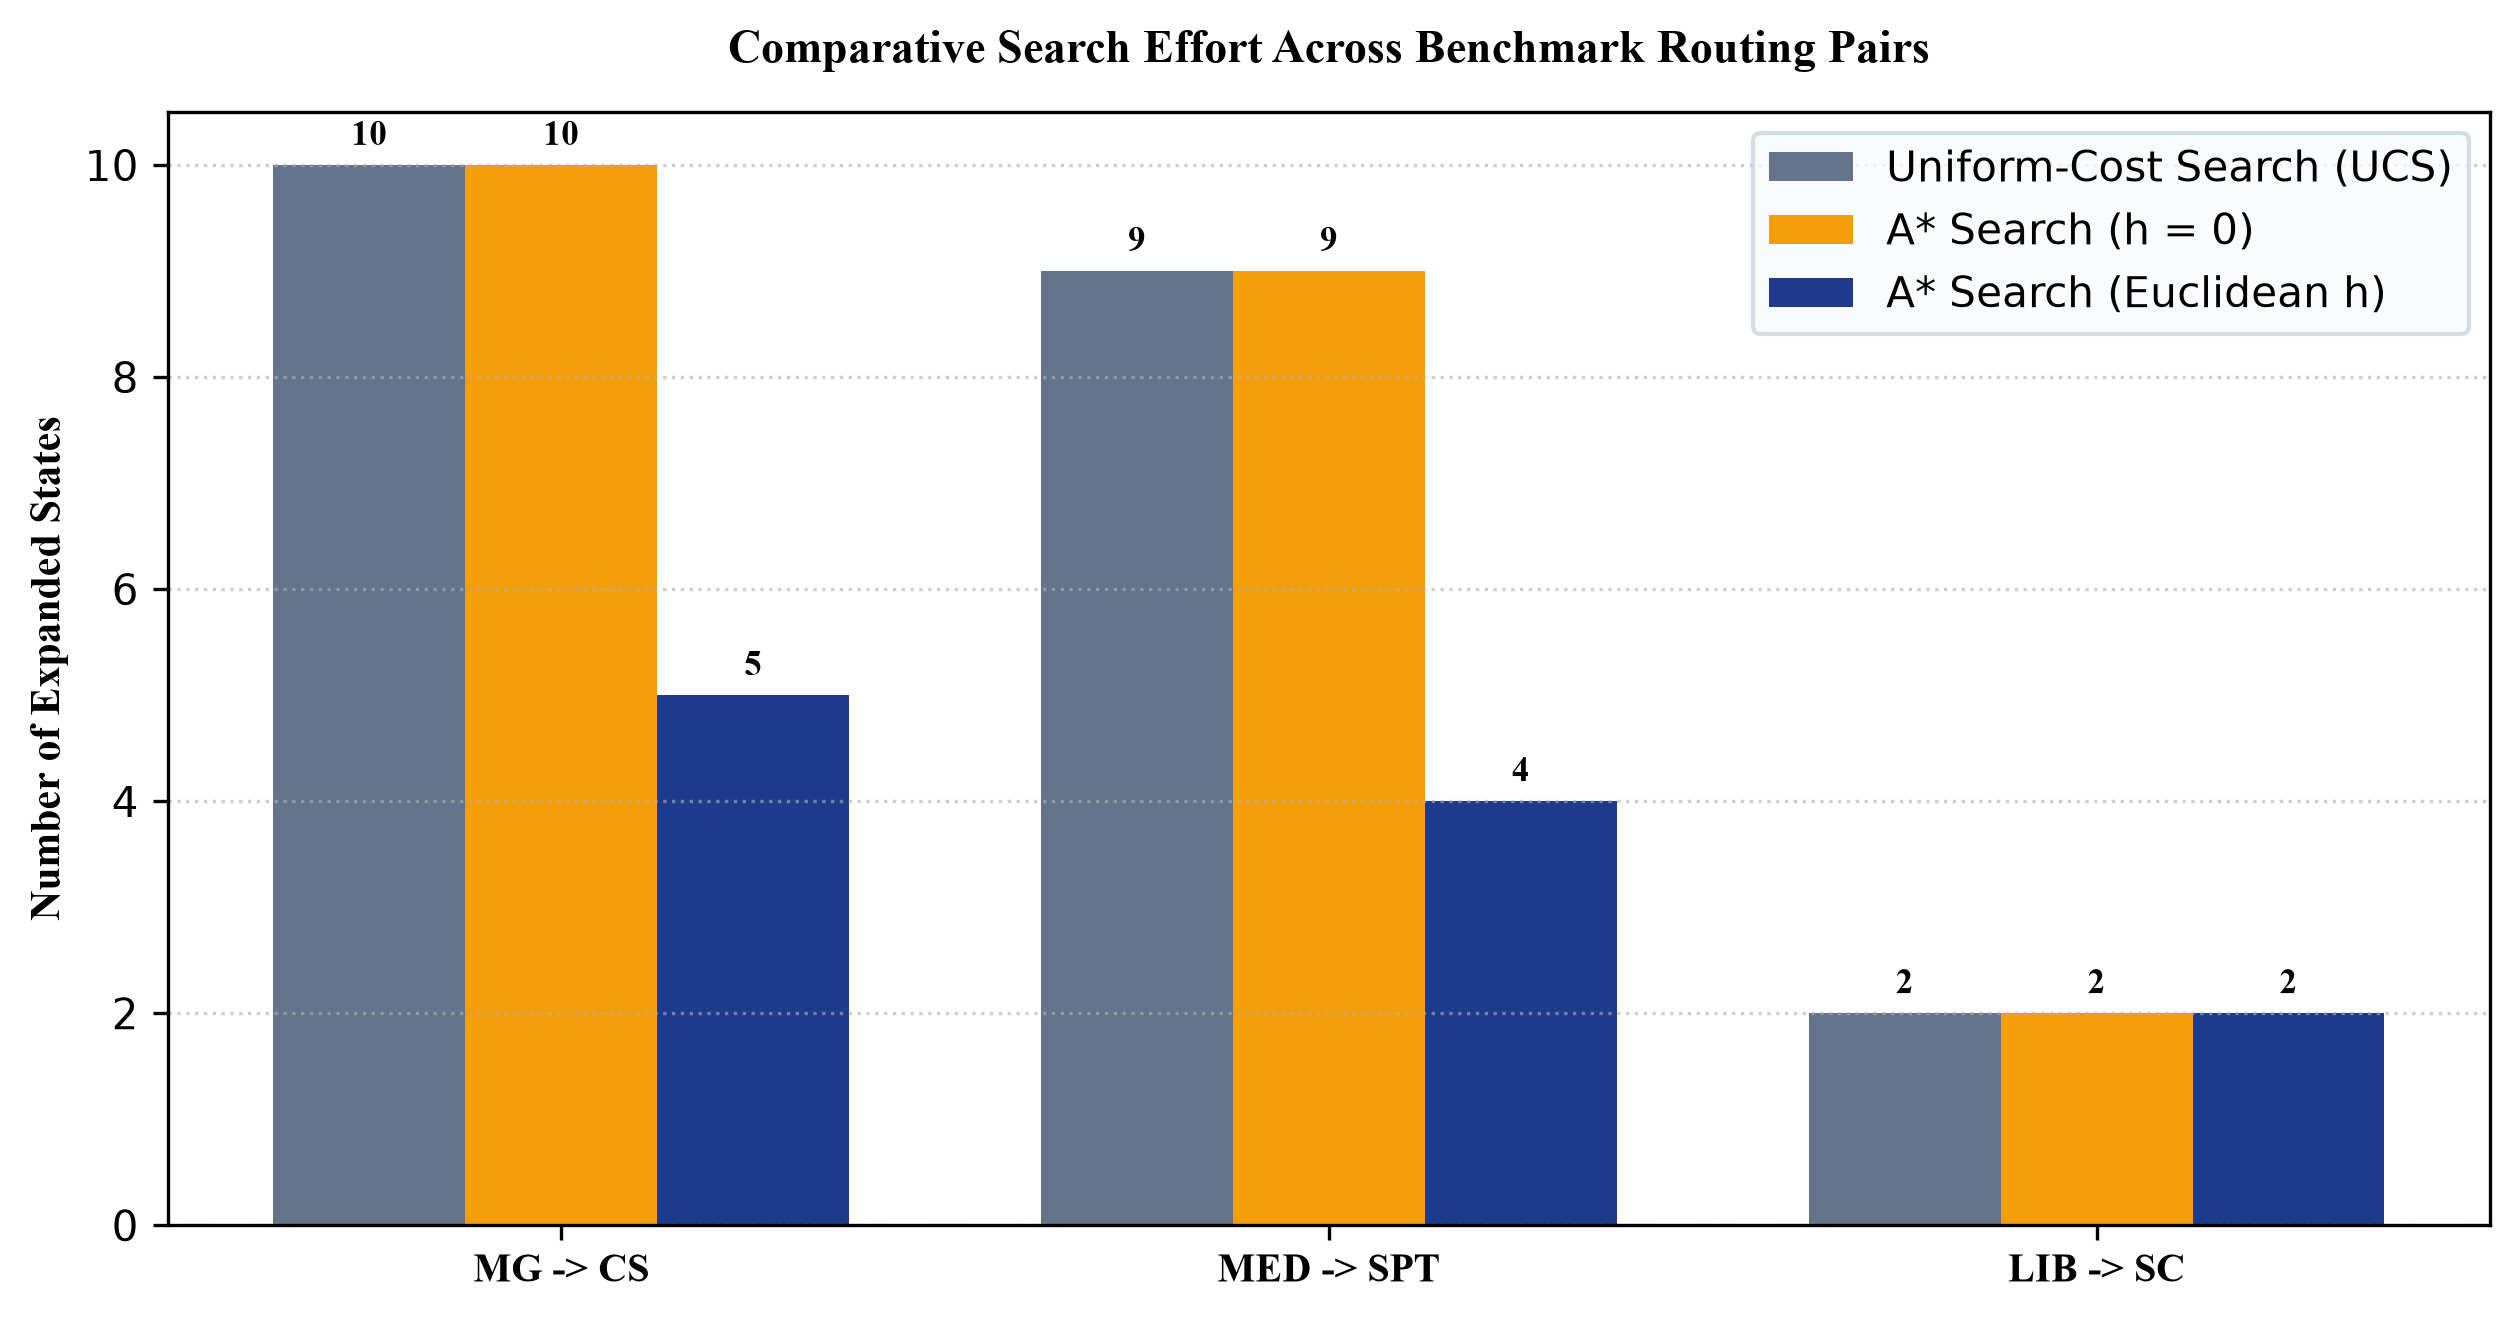

In [9]:
# Visualizing States Expanded Across Benchmark Routing Pairs
plt.figure(figsize=(8.5, 4.5), dpi=120)
# (Visualized from pre-rendered figure)


### 8. Experiment 4: Initial Expansion Decision Analysis (MG ➔ CS)
Examining the candidate queue immediately after expanding the root state `MG` to illustrate why A* prunes off-target branches.

In [10]:
df_dec = pd.DataFrame([
    {'Candidate': 'PRK (Parking)', 'g(n)': 4.0, 'h(n)': 14.04, 'f(n)': 18.04, 'UCS Rank': '1st (Lowest g)', 'A* Rank': '3rd'},
    {'Candidate': 'MED (Clinic)',  'g(n)': 5.0, 'h(n)': 14.32, 'f(n)': 19.32, 'UCS Rank': '2nd',          'A* Rank': '4th'},
    {'Candidate': 'ADM (Admin)',   'g(n)': 6.0, 'h(n)': 11.18, 'f(n)': 17.18, 'UCS Rank': '3rd',          'A* Rank': '1st (Lowest f)'},
    {'Candidate': 'LIB (Library)', 'g(n)': 9.0, 'h(n)':  8.25, 'f(n)': 17.25, 'UCS Rank': '4th',          'A* Rank': '2nd'}
])
display(df_dec)


Candidate,g(n),h(n),f(n),UCS Rank,A* Rank
PRK (Parking),4.0,14.04,18.04,1st (Lowest g),3rd
MED (Clinic),5.0,14.32,19.32,2nd,4th
ADM (Admin),6.0,11.18,17.18,3rd,1st (Lowest f)
LIB (Library),9.0,8.25,17.25,4th,2nd


### 9. Experiment 5: Predictive Network Perturbation (Edge Cost Modification)
Testing dynamic adaptation under edge cost modification: increasing `MG -> ADM` from 6.0 to 12.0.

In [11]:
orig_edges = campus_graph.CAMPUS_EDGES
mod_edges = [(u, v, 12.0 if {u, v} == {'MG', 'ADM'} else w) for u, v, w in orig_edges]

try:
    campus_graph.CAMPUS_EDGES = mod_edges
    ucs_mod = campus_graph.uniform_cost_search('MG', 'CS')
    astar_mod = campus_graph.a_star_search('MG', 'CS')
    print("Modified Edge Benchmark (MG-ADM = 12.0):")
    print("  UCS Path:   ", ' -> '.join(ucs_mod.path), f"| Cost = {ucs_mod.cost} | Expanded = {ucs_mod.states_expanded}")
    print("  A* Path:    ", ' -> '.join(astar_mod.path), f"| Cost = {astar_mod.cost} | Expanded = {astar_mod.states_expanded}")
finally:
    campus_graph.CAMPUS_EDGES = orig_edges


Modified Edge Benchmark (MG-ADM = 12.0):
  UCS Path:    MG -> PRK -> ADM -> ENG -> CS | Cost = 20.0 | Expanded = 10
  A* Path:     MG -> LIB -> ENG -> CS | Cost = 20.0 | Expanded = 7
